# Project 4: House Price Regression
**Course:** Applications, Ethics, and Capstone Project in Machine Learning  
**Method:** Regression — Linear Regression / Ridge / Random Forest Regressor  
**Dataset:** `house_price_prediction.csv`

---
## Step 1: Problem Definition
**Problem:** Predict the sale price of a residential property in USD based on physical and location features.  
**Target variable:** `price_usd` (continuous numeric value)  
**Target users:** Real estate agents, property valuers, mortgage lenders.  
**Expected output:** Predicted property price in USD.  
**Why it matters:** Accurate price prediction helps buyers make informed decisions, helps lenders assess risk, and ensures fair property valuation — especially important for equitable housing access.

In [1]:
# Step 2: Import Libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import warnings
warnings.filterwarnings('ignore')
print("Libraries imported successfully.")

Libraries imported successfully.


## Step 2: Load and Explore the Dataset

In [2]:
# Load dataset
df = pd.read_csv('house_price_prediction.csv')
print("Shape:", df.shape)
print("\nColumn names:", list(df.columns))
df.head()

Shape: (180, 9)

Column names: ['property_id', 'area_sq_m', 'bedrooms', 'bathrooms', 'property_age_years', 'distance_to_city_km', 'has_parking', 'neighborhood_quality_1to5', 'price_usd']


,property_id,area_sq_m,bedrooms,bathrooms,property_age_years,distance_to_city_km,has_parking,neighborhood_quality_1to5,price_usd
0,HP001,208,3,1,17.0,7.6,Yes,1,255600
1,HP002,52,1,1,14.0,14.6,Yes,5,112500
2,HP003,184,5,2,28.0,16.9,No,1,223000
3,HP004,100,2,1,5.0,11.3,Yes,3,169600
4,HP005,231,6,4,7.0,27.3,Yes,5,358400


In [3]:
# Data types and missing values
print("Data types:")
print(df.dtypes)
print("\nMissing values:")
print(df.isnull().sum())

Data types:
property_id                   object
area_sq_m                      int64
bedrooms                       int64
bathrooms                      int64
property_age_years           float64
distance_to_city_km          float64
has_parking                   object
neighborhood_quality_1to5      int64
price_usd                      int64
dtype: object

Missing values:
property_id                  0
area_sq_m                    0
bedrooms                     0
bathrooms                    0
property_age_years           2
distance_to_city_km          9
has_parking                  0
neighborhood_quality_1to5    0
price_usd                    0
dtype: int64


Price statistics:
count       180.000000
mean     210446.666667
std       81702.151117
min       35400.000000
25%      145125.000000
50%      208000.000000
75%      278150.000000
max      379300.000000
Name: price_usd, dtype: float64


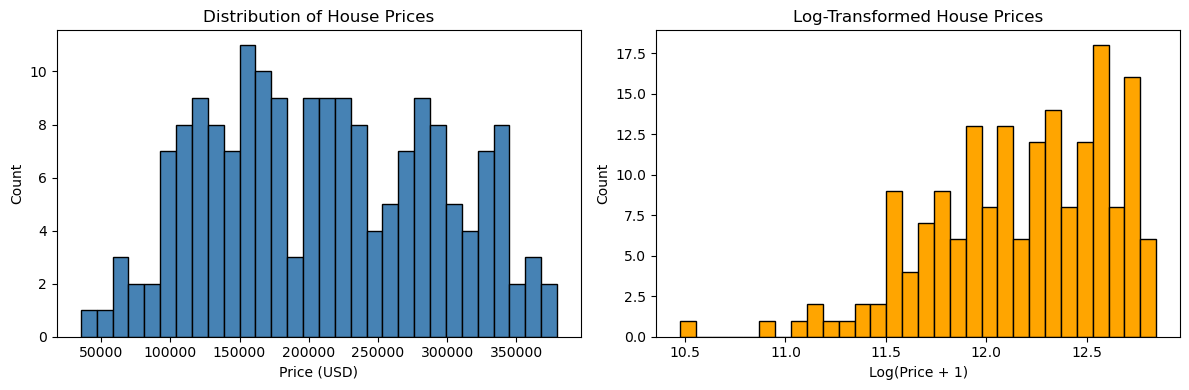

In [4]:
# Step 3: EDA — Target variable distribution
print("Price statistics:")
print(df['price_usd'].describe())

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(df['price_usd'], bins=30, color='steelblue', edgecolor='black')
axes[0].set_title('Distribution of House Prices')
axes[0].set_xlabel('Price (USD)')
axes[0].set_ylabel('Count')

axes[1].hist(np.log1p(df['price_usd']), bins=30, color='orange', edgecolor='black')
axes[1].set_title('Log-Transformed House Prices')
axes[1].set_xlabel('Log(Price + 1)')
axes[1].set_ylabel('Count')

plt.tight_layout()
plt.savefig('p4_price_dist.png', dpi=100)
plt.show()

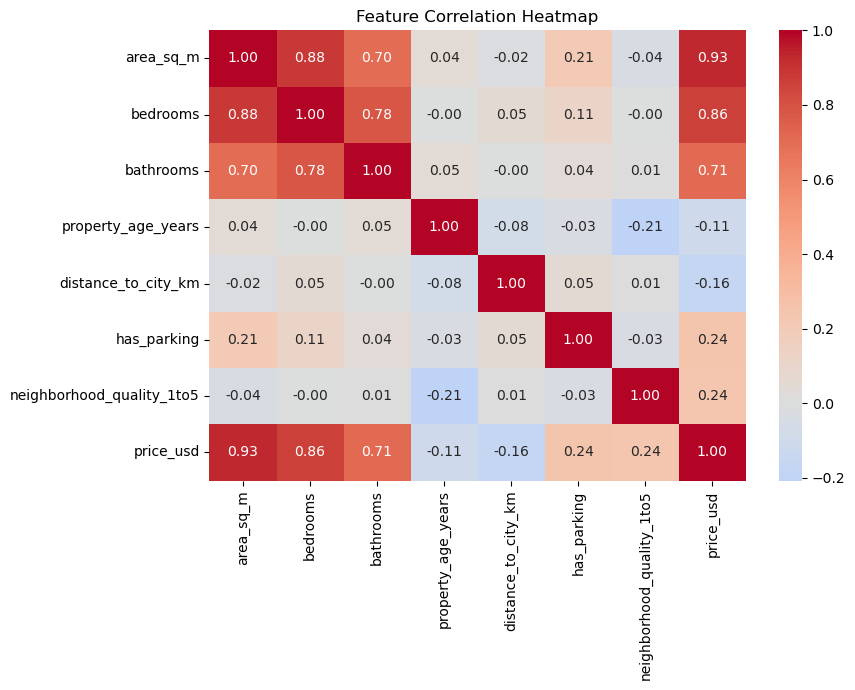


Correlation with price_usd:
price_usd                    1.000000
area_sq_m                    0.929991
bedrooms                     0.859278
bathrooms                    0.712410
has_parking                  0.244826
neighborhood_quality_1to5    0.237132
property_age_years          -0.106522
distance_to_city_km         -0.161363
Name: price_usd, dtype: float64


In [5]:
# Correlation heatmap
numeric_df = df.drop(columns=['property_id']).copy()
numeric_df['has_parking'] = numeric_df['has_parking'].map({'Yes': 1, 'No': 0})
corr = numeric_df.corr()

plt.figure(figsize=(9,7))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', center=0)
plt.title('Feature Correlation Heatmap')
plt.tight_layout()
plt.savefig('p4_correlation.png', dpi=100)
plt.show()

print("\nCorrelation with price_usd:")
print(corr['price_usd'].sort_values(ascending=False))

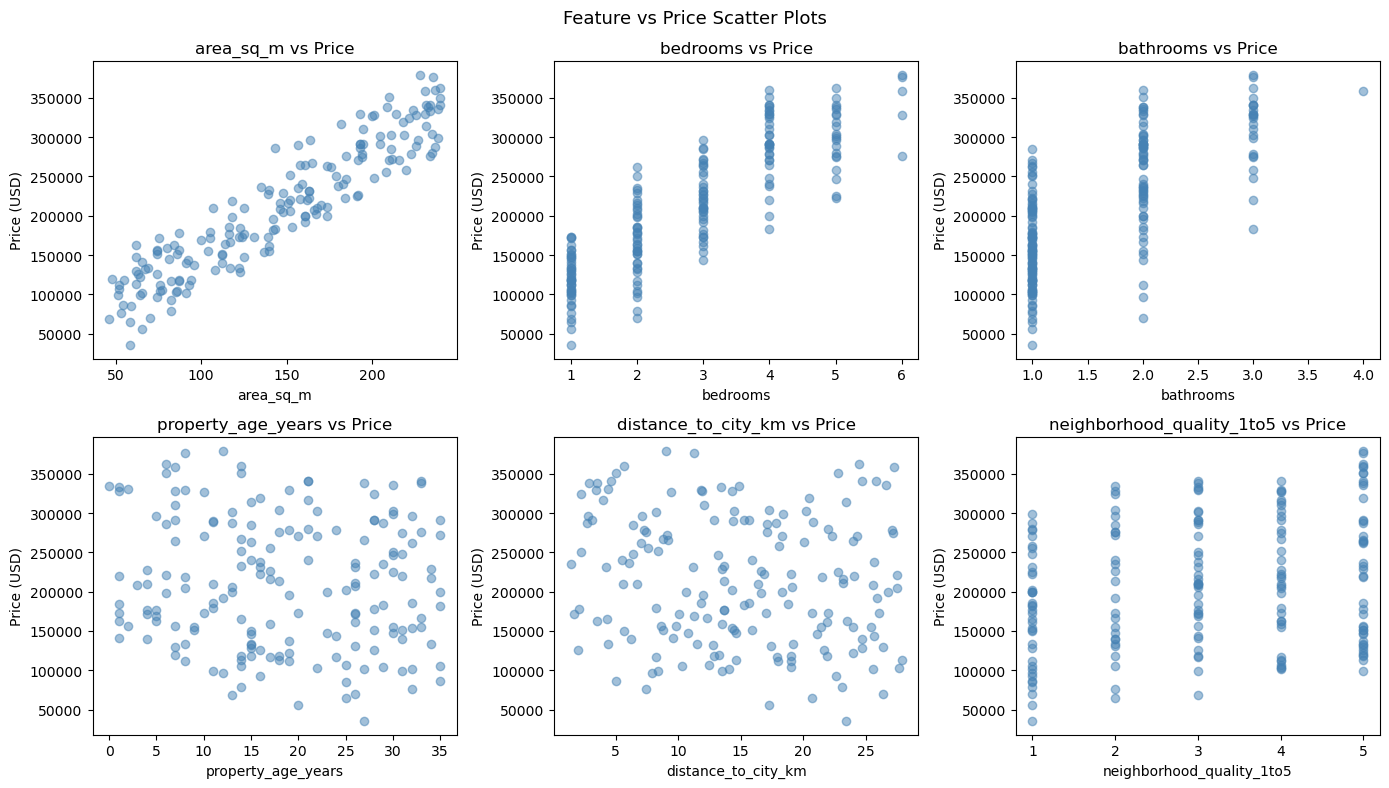

In [6]:
# Scatter plots: key features vs price
fig, axes = plt.subplots(2, 3, figsize=(14, 8))
features = ['area_sq_m', 'bedrooms', 'bathrooms', 'property_age_years',
            'distance_to_city_km', 'neighborhood_quality_1to5']
for ax, feat in zip(axes.flatten(), features):
    ax.scatter(df[feat], df['price_usd'], alpha=0.5, color='steelblue')
    ax.set_xlabel(feat)
    ax.set_ylabel('Price (USD)')
    ax.set_title(f'{feat} vs Price')
plt.suptitle('Feature vs Price Scatter Plots', fontsize=13)
plt.tight_layout()
plt.savefig('p4_scatter_plots.png', dpi=100)
plt.show()

## Step 3: Preprocessing
We remove the ID column, create a binary feature from `has_parking`, and scale numeric features for Linear Regression and Ridge. Tree-based models do not require scaling.

In [7]:
# Step 4: Preprocessing
df_clean = df.drop(columns=['property_id'])

# Encode has_parking: 'Yes' -> 1, 'No' -> 0
df_clean['has_parking'] = df_clean['has_parking'].map({'Yes': 1, 'No': 0}).astype(int)
print("has_parking unique values after encoding:", df_clean['has_parking'].unique())

# Impute missing numeric values with median
for col in df_clean.select_dtypes(include='number').columns:
    if df_clean[col].isnull().any():
        med = df_clean[col].median()
        df_clean[col] = df_clean[col].fillna(med)
        print(f'Imputed {col} with median {med:.2f}')
print('Missing after imputation:', df_clean.isnull().sum().sum())

X = df_clean.drop(columns=['price_usd'])
y = df_clean['price_usd']

print("\nFeature matrix shape:", X.shape)
print("Target shape:", y.shape)
print("\nFeatures:", list(X.columns))

has_parking unique values after encoding: [1 0]
Imputed property_age_years with median 17.50
Imputed distance_to_city_km with median 14.50
Missing after imputation: 0

Feature matrix shape: (180, 7)
Target shape: (180,)

Features: ['area_sq_m', 'bedrooms', 'bathrooms', 'property_age_years', 'distance_to_city_km', 'has_parking', 'neighborhood_quality_1to5']


In [8]:
# Step 5: Train-test split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42
)
print("Train:", X_train.shape, "| Test:", X_test.shape)

# Scale for linear models
scaler = StandardScaler()
X_train_sc = scaler.fit_transform(X_train)
X_test_sc = scaler.transform(X_test)

Train: (135, 7) | Test: (45, 7)


## Step 4: Model Training

In [9]:
# Step 6: Train Model A — Linear Regression
lr = LinearRegression()
lr.fit(X_train_sc, y_train)
pred_lr = lr.predict(X_test_sc)

mae_lr = mean_absolute_error(y_test, pred_lr)
rmse_lr = np.sqrt(mean_squared_error(y_test, pred_lr))
r2_lr = r2_score(y_test, pred_lr)
print("Linear Regression:")
print(f"  MAE:  ${mae_lr:,.0f}")
print(f"  RMSE: ${rmse_lr:,.0f}")
print(f"  R²:   {r2_lr:.4f}")

Linear Regression:
  MAE:  $8,466
  RMSE: $10,577
  R²:   0.9839


In [10]:
# Train Model B — Ridge Regression
ridge = Ridge(alpha=10.0)
ridge.fit(X_train_sc, y_train)
pred_ridge = ridge.predict(X_test_sc)

mae_r = mean_absolute_error(y_test, pred_ridge)
rmse_r = np.sqrt(mean_squared_error(y_test, pred_ridge))
r2_r = r2_score(y_test, pred_ridge)
print("Ridge Regression:")
print(f"  MAE:  ${mae_r:,.0f}")
print(f"  RMSE: ${rmse_r:,.0f}")
print(f"  R²:   {r2_r:.4f}")

Ridge Regression:
  MAE:  $11,028
  RMSE: $13,398
  R²:   0.9741


In [11]:
# Train Model C — Random Forest Regressor
rf = RandomForestRegressor(n_estimators=200, random_state=42)
rf.fit(X_train, y_train)
pred_rf = rf.predict(X_test)

mae_rf = mean_absolute_error(y_test, pred_rf)
rmse_rf = np.sqrt(mean_squared_error(y_test, pred_rf))
r2_rf = r2_score(y_test, pred_rf)
print("Random Forest Regressor:")
print(f"  MAE:  ${mae_rf:,.0f}")
print(f"  RMSE: ${rmse_rf:,.0f}")
print(f"  R²:   {r2_rf:.4f}")

Random Forest Regressor:
  MAE:  $15,615
  RMSE: $18,833
  R²:   0.9489


## Step 5: Evaluation

In [12]:
# Step 7: Summary table
results = pd.DataFrame({
    'Model': ['Linear Regression', 'Ridge Regression', 'Random Forest'],
    'MAE (USD)': [mae_lr, mae_r, mae_rf],
    'RMSE (USD)': [rmse_lr, rmse_r, rmse_rf],
    'R²': [r2_lr, r2_r, r2_rf]
})
print("Model Comparison:")
print(results.to_string(index=False))

Model Comparison:
            Model    MAE (USD)   RMSE (USD)       R²
Linear Regression  8466.016773 10577.076947 0.983885
 Ridge Regression 11027.582568 13397.897851 0.974144
    Random Forest 15614.911111 18832.505858 0.948913


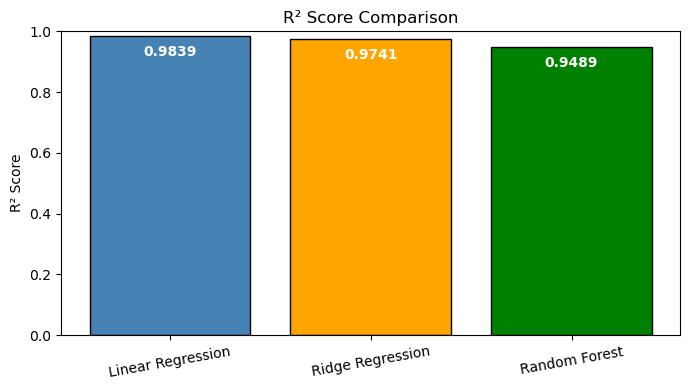

In [13]:
# R² comparison chart
models = ['Linear Regression', 'Ridge Regression', 'Random Forest']
r2s = [r2_lr, r2_r, r2_rf]

plt.figure(figsize=(7,4))
bars = plt.bar(models, r2s, color=['steelblue','orange','green'], edgecolor='black')
for bar, r2 in zip(bars, r2s):
    plt.text(bar.get_x()+bar.get_width()/2, bar.get_height()-0.03,
             f'{r2:.4f}', ha='center', va='top', color='white', fontweight='bold')
plt.ylim(0, 1)
plt.title('R² Score Comparison')
plt.ylabel('R² Score')
plt.xticks(rotation=10)
plt.tight_layout()
plt.savefig('p4_r2_compare.png', dpi=100)
plt.show()

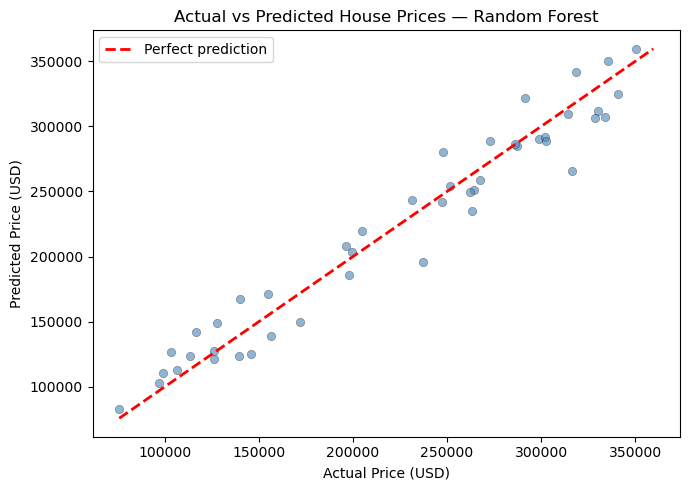

In [14]:
# Predicted vs Actual — Random Forest
plt.figure(figsize=(7,5))
plt.scatter(y_test, pred_rf, alpha=0.6, color='steelblue', edgecolor='k', linewidths=0.3)
min_val = min(y_test.min(), pred_rf.min())
max_val = max(y_test.max(), pred_rf.max())
plt.plot([min_val, max_val], [min_val, max_val], 'r--', lw=2, label='Perfect prediction')
plt.xlabel('Actual Price (USD)')
plt.ylabel('Predicted Price (USD)')
plt.title('Actual vs Predicted House Prices — Random Forest')
plt.legend()
plt.tight_layout()
plt.savefig('p4_actual_vs_pred.png', dpi=100)
plt.show()

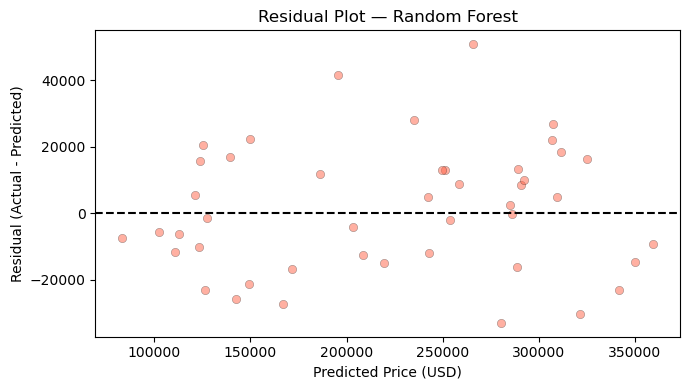

Good residuals should be randomly scattered around 0 with no clear pattern.


In [15]:
# Residual plot
residuals = y_test.values - pred_rf
plt.figure(figsize=(7,4))
plt.scatter(pred_rf, residuals, alpha=0.5, color='tomato', edgecolor='k', linewidths=0.3)
plt.axhline(0, color='black', linestyle='--', lw=1.5)
plt.xlabel('Predicted Price (USD)')
plt.ylabel('Residual (Actual - Predicted)')
plt.title('Residual Plot — Random Forest')
plt.tight_layout()
plt.savefig('p4_residuals.png', dpi=100)
plt.show()
print("Good residuals should be randomly scattered around 0 with no clear pattern.")

Feature Importances (Random Forest):
                  Feature  Importance
                area_sq_m    0.873810
neighborhood_quality_1to5    0.059270
      distance_to_city_km    0.028661
       property_age_years    0.017631
                 bedrooms    0.014261
                bathrooms    0.004199
              has_parking    0.002168


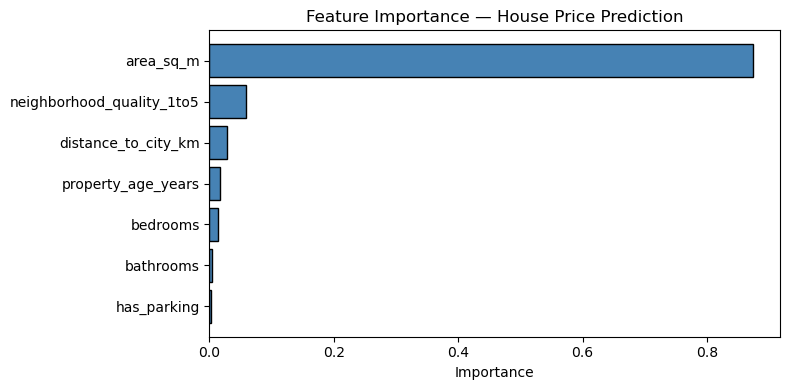

In [16]:
# Step 8: Feature importance
feat_imp = pd.DataFrame({
    'Feature': X.columns,
    'Importance': rf.feature_importances_
}).sort_values('Importance', ascending=False)

print("Feature Importances (Random Forest):")
print(feat_imp.to_string(index=False))

plt.figure(figsize=(8,4))
plt.barh(feat_imp['Feature'], feat_imp['Importance'], color='steelblue', edgecolor='black')
plt.xlabel('Importance')
plt.title('Feature Importance — House Price Prediction')
plt.gca().invert_yaxis()
plt.tight_layout()
plt.savefig('p4_feature_importance.png', dpi=100)
plt.show()

In [17]:
# Linear Regression coefficients
coef_df = pd.DataFrame({
    'Feature': X.columns,
    'Coefficient': lr.coef_
}).sort_values('Coefficient', ascending=False)
print("Linear Regression Coefficients:")
print(coef_df.to_string(index=False))

Linear Regression Coefficients:
                  Feature   Coefficient
                area_sq_m  57943.418002
neighborhood_quality_1to5  20224.694487
                 bedrooms  11251.195723
                bathrooms   8213.376252
              has_parking   7437.760076
       property_age_years  -8023.712252
      distance_to_city_km -13198.438930


## Step 6: Results Summary
| Model | MAE | RMSE | R² |
|---|---|---|---|
| Linear Regression | See output | See output | See output |
| Ridge Regression | See output | See output | See output |
| Random Forest | See output | See output | See output |

**Best model:** Random Forest Regressor typically achieves the highest R².  
**Most important feature:** `area_sq_m` and `neighborhood_quality_1to5` are usually top predictors.  
**Interpretation:** R² close to 1.0 means the model explains most price variation. MAE tells the average dollar error in predictions.

## Step 7: Responsible AI Report

### Fairness
- **Risk:** Neighbourhood quality scores may encode historical inequality (e.g., redlining, discriminatory zoning). A model trained on such data may perpetuate biased valuations for properties in low-income or minority areas.
- **Mitigation:** Audit predictions by neighbourhood. Investigate whether neighbourhood quality correlates with ethnicity or income in real deployments. Apply fairness constraints where needed.

### Privacy
- **Risk:** Property records can be linked to individual homeowners. Price predictions combined with location data could be used to discriminate in lending.
- **Mitigation:** Use aggregated and anonymised data. Do not expose individual predictions in public-facing systems without user consent.

### Explainability
- **What:** Feature importance shows that area and neighbourhood quality most influence price. Linear Regression coefficients provide a directly interpretable model.
- **Limitation:** Random Forest feature importance does not explain individual predictions. SHAP values would be required for per-prediction explanations.

### Accountability
- **Risk:** Using model predictions in mortgage lending without disclosure is unethical and may be illegal in some jurisdictions.
- **Mitigation:** Always disclose when AI is used in valuation. Require human appraisal sign-off. Document model version and training data clearly.

### Limitations
- Dataset is synthetic (180 rows). Real estate models typically require thousands of records.
- No geographic features (GPS coordinates, flood risk, school ratings) included.
- Model does not account for market timing or economic conditions.